### Plot ABES and Doppler measuring points in magnetic topology

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import flap

sys.path.append('/home/smarci/python_libs')
import flap_w7x_abes
from poloidal_flow import ABESConfig, ABESDataReader

INIT flap storage
Importing flap_w7x_abes
Importing w7x_webapi


In [3]:
dev_r = ABESDataReader(
    ABESConfig('20250409.046', True)
).read_spatial_calibration()

poincare = np.load('20250409_046_poincare.npy', allow_pickle=True)
d = np.loadtxt("doppler/20250409.45_QMR-W1_sweep_12_high_ECRH.txt", delimiter="\t", skiprows=1)

In [4]:
r = np.sqrt(d[:, 0]**2 + d[:, 1]**2)
z = d[:, 2]

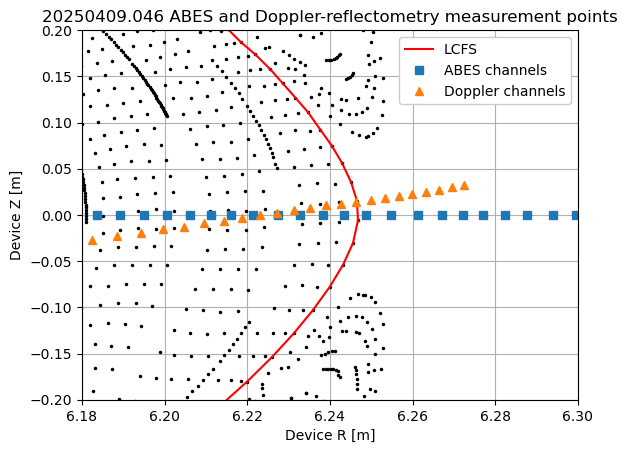

In [5]:
plt.xlabel('Device R [m]')
plt.ylabel('Device Z [m]')
plt.title('20250409.046 ABES and Doppler-reflectometry measurement points')

plt.xlim(6.18, 6.3)
plt.ylim(-0.2, 0.2)

plt.plot(poincare[:, :, 0], poincare[:, :, 1], ls = 'none', marker = 'o', markersize = 1.5, c = 'k')
plt.plot(*poincare[0, :, :].T, label = 'LCFS', c = 'r')
plt.plot(dev_r, np.zeros_like(dev_r), marker = 's', c = 'tab:blue', ls = 'None', label = 'ABES channels')
plt.plot(r, z, marker = '^', color = 'tab:orange', markersize = 6, ls = 'None', label = 'Doppler channels')

plt.grid()
plt.legend(framealpha = True)

plt.savefig('../plots/abes_doppler_pos.pdf')